# 45. Interpolation, Implicit Bias and Kernels
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Double descent for minimum-norm least squares with $N=100$ samples and $d$ isotropic Gaussian features ($\norm\beta^2=1$, noise variance $\sigma^2=0.25$). Dots: simulated excess risk $\mathbb E\norm{\hat w-\beta}^2$ (average of $40$ trials); solid curve: the exact formula of [@thm-min-norm-risk]. The risk rises toward the interpolation threshold $d=N$ (dotted), diverges there, and descends again in the over-parametrized regime. With ridge regularization at the Bayes-optimal level $\lambda=\sigma^2d/\norm\beta^2$ (red), the peak disappears.

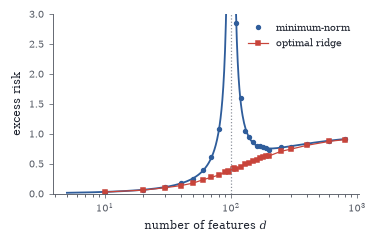

In [2]:
rng = np.random.default_rng(0); Nn = 100; sig2 = 0.25; ds = np.r_[np.arange(10, 91, 10), 95, 97, 103, 105, np.arange(110, 201, 10), 250, 300, 400, 600, 800]; mn, rr = [], []
for d in ds:
    a, b = [], []
    for _ in range(40):
        beta = rng.normal(size=d); beta /= np.linalg.norm(beta); X = rng.normal(size=(Nn, d)); y = X @ beta + np.sqrt(sig2) * rng.normal(size=Nn)
        a.append(np.sum((np.linalg.pinv(X) @ y - beta) ** 2)); lam = sig2 * d; b.append(np.sum((np.linalg.solve(X.T @ X + lam * np.eye(d), X.T @ y) - beta) ** 2))
    mn.append(np.mean(a)); rr.append(np.mean(b))
dd1 = np.linspace(5, Nn - 2.5, 200); dd2 = np.linspace(Nn + 2.5, 800, 400)
fig, ax = plt.subplots(figsize=(W * 0.72, 2.1))
ax.plot(dd1, sig2 * dd1 / (Nn - dd1 - 1), color=BLUE); ax.plot(dd2, (1 - Nn / dd2) + sig2 * Nn / (dd2 - Nn - 1), color=BLUE); ax.plot(ds, mn, "o", color=BLUE, ms=2.5, label="minimum-norm")
ax.plot(ds, rr, "s-", color=RED, ms=2.2, lw=0.8, label="optimal ridge"); ax.axvline(Nn, color=GRAY, ls=":", lw=0.8)
ax.set_xscale("log"); ax.set_ylim(0, 3); ax.set_xlabel("number of features $d$"); ax.set_ylabel("excess risk"); ax.legend(fontsize=6.5, frameon=False)

Benign and harmful interpolation. Excess risk of the minimum-norm interpolant against the number of samples $N$ (noise variance $0.25$, dotted). Blue: $d=5000$ features with covariance eigenvalues $1$ (five signal directions) and $0.02$ (the other $4995$); although the training data, noise included, are fitted exactly, the risk falls toward zero as $N$ grows. Red: $d=400$ isotropic features, where interpolation is harmful near $N=d$.

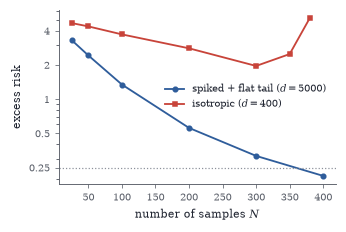

In [3]:
rng = np.random.default_rng(1); sig = 0.5
def mnrisk(n, lamv, beta, T=12):
    r = []
    for _ in range(T):
        X = rng.normal(size=(n, len(lamv))) * np.sqrt(lamv); y = X @ beta + sig * rng.normal(size=n); w = np.linalg.lstsq(X, y, rcond=None)[0]; r.append(np.sum(lamv * (w - beta) ** 2))
    return np.mean(r)
d1 = 5000; lam1 = np.r_[np.ones(5), np.full(d1 - 5, 0.02)]; b1 = np.r_[np.ones(5), np.zeros(d1 - 5)]
lam2 = np.ones(400); b2 = np.r_[np.ones(5), np.zeros(395)]
ns = [25, 50, 100, 200, 300, 400]; ns2 = [25, 50, 100, 200, 300, 350, 380]
fig, ax = plt.subplots(figsize=(W * 0.66, 2.0))
ax.semilogy(ns, [mnrisk(n, lam1, b1) for n in ns], "o-", color=BLUE, ms=3, label="spiked + flat tail ($d=5000$)"); ax.semilogy(ns2, [mnrisk(n, lam2, b2) for n in ns2], "s-", color=RED, ms=3, label="isotropic ($d=400$)")
ax.axhline(sig**2, color=GRAY, ls=":", lw=0.8); ax.set_yticks([0.25, 0.5, 1, 2, 4]); ax.set_yticklabels(["0.25", "0.5", "1", "2", "4"]); ax.yaxis.set_minor_formatter(plt.NullFormatter()); ax.set_xlabel("number of samples $N$"); ax.set_ylabel("excess risk"); ax.legend(fontsize=6.3, frameon=False)

Implicit bias toward the maximum margin. Left: linearly separable data and the separating lines of gradient descent on the logistic loss after $10$, $10^2$, $10^3$ and $10^5$ steps (light to dark blue), which rotate slowly toward the hard-margin SVM separator (red, dashed); support vectors are circled. Right: the angle between $w_t$ and the SVM direction against $t$ (log scale) decays like $1/\log t$, while $\norm{w_t}$ grows like $\log t$.

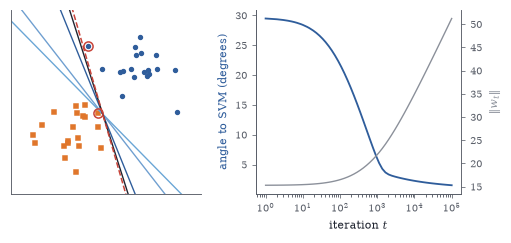

In [4]:
from scipy.optimize import minimize
rng = np.random.default_rng(3); Xp = rng.normal(size=(20, 2)) * 0.6 + [1.2, 1.6]; Xn = rng.normal(size=(20, 2)) * 0.6 + [-1.0, -0.4]; Xc = np.r_[Xp, Xn]; yc = np.r_[np.ones(20), -np.ones(20)]
Z = yc[:, None] * Xc; cons = {"type": "ineq", "fun": lambda w: Z @ w - 1}; wsvm = minimize(lambda w: w @ w, np.array([1.0, 1.0]), constraints=[cons], method="SLSQP").x
w = np.zeros(2); snaps = {}; ts = np.unique(np.round(np.geomspace(1, 1e5, 60)).astype(int)); ang, nrm = [], []
for t in range(1, 100001):
    mgn = Z @ w; w = w + 0.5 * Z.T @ (1 / (1 + np.exp(np.minimum(mgn, 700))))
    if t in (10, 100, 1000, 100000): snaps[t] = w.copy()
    if t in ts: ang.append(np.degrees(np.arccos(np.clip(w @ wsvm / np.linalg.norm(w) / np.linalg.norm(wsvm), -1, 1)))); nrm.append(np.linalg.norm(w))
fig, axs = plt.subplots(1, 2, figsize=(W, 2.1)); xl = np.linspace(-3, 3.2, 10)
axs[0].plot(Xp[:, 0], Xp[:, 1], "o", color=BLUE, ms=2.5); axs[0].plot(Xn[:, 0], Xn[:, 1], "s", color=ORANGE, ms=2.5)
for (t, wv), c in zip(snaps.items(), [SKY, "#6f9fd0", BLUE, INK]): axs[0].plot(xl, -wv[0] / wv[1] * xl, color=c, lw=0.9)
axs[0].plot(xl, -wsvm[0] / wsvm[1] * xl, "--", color=RED, lw=1.0); sv = np.abs(Z @ wsvm - 1) < 1e-3; axs[0].plot(Xc[sv, 0], Xc[sv, 1], "o", mfc="none", mec=RED, ms=6)
axs[0].set_xlim(-3, 3.2); axs[0].set_ylim(-2.6, 3.4); axs[0].set_aspect("equal"); axs[0].set_xticks([]); axs[0].set_yticks([])
axs[1].semilogx(ts[: len(ang)], ang, color=BLUE); axs[1].set_xlabel("iteration $t$"); axs[1].set_ylabel("angle to SVM (degrees)", color=BLUE)
ax2 = axs[1].twinx(); ax2.semilogx(ts[: len(nrm)], nrm, color=GRAY, lw=0.9); ax2.set_ylabel(r"$\|w_t\|$", color=GRAY); ax2.spines["right"].set_visible(True)

Implicit low-rank bias of factorized gradient descent ($W=UV^{T}$, $30\times30$ factors). Left: fitting a rank-3 target with singular values $3$, $2$, $1$ from a small initialization; the singular values of $W$ are learned one at a time, in order of strength, each along a logistic curve (dashed: the formula $a(t)$ with $a_0$ matched to the initialization), while the remaining $27$ stay near zero. Right: matrix completion from $30\%$ of the entries of the same target; all runs fit the observed entries, but the error on the unobserved entries grows with the initialization scale, as the solution found departs from low rank.

Text(0, 0.5, 'relative error, unobserved')

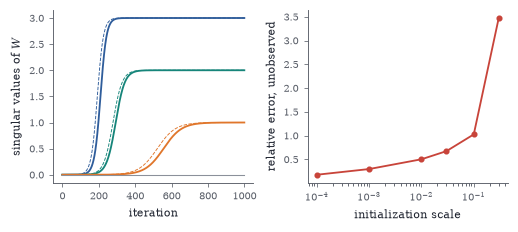

In [5]:
rng = np.random.default_rng(0); n = 30; Ua, _ = np.linalg.qr(rng.normal(size=(n, 3))); Va, _ = np.linalg.qr(rng.normal(size=(n, 3))); M = Ua @ np.diag([3.0, 2, 1]) @ Va.T
U = rng.normal(size=(n, n)) * 1e-3; V = rng.normal(size=(n, n)) * 1e-3; eta = 0.01; sv = []
for t in range(1000): R = U @ V.T - M; U, V = U - eta * R @ V, V - eta * R.T @ U; sv.append(np.linalg.svd(U @ V.T, compute_uv=False)[:5])
sv = np.array(sv); fig, axs = plt.subplots(1, 2, figsize=(W, 2.0)); tt = np.arange(1000)
for k, (s, c) in enumerate(zip([3, 2, 1], [BLUE, TEAL, ORANGE])):
    axs[0].plot(tt, sv[:, k], color=c); a0 = 3e-5; axs[0].plot(tt, s / (1 + (s / a0 - 1) * np.exp(-2 * s * eta * tt)), "--", color=c, lw=0.6)
axs[0].plot(tt, sv[:, 3], color=GRAY, lw=0.7); axs[0].set_xlabel("iteration"); axs[0].set_ylabel("singular values of $W$")
mask = rng.uniform(size=(n, n)) < 0.3; scales = [1e-4, 1e-3, 1e-2, 3e-2, 0.1, 0.3]; te = []
for sc in scales:
    g = np.random.default_rng(1); U = g.normal(size=(n, n)) * sc; V = g.normal(size=(n, n)) * sc
    for t in range(15000): R = mask * (U @ V.T - M); U, V = U - 0.1 * R @ V, V - 0.1 * R.T @ U
    te.append(np.linalg.norm((~mask) * (U @ V.T - M)) / np.linalg.norm((~mask) * M))
axs[1].semilogx(scales, te, "o-", color=RED, ms=3); axs[1].set_xlabel("initialization scale"); axs[1].set_ylabel("relative error, unobserved")

The neural tangent kernel of a two-layer ReLU network of width $m=8000$ on $64$ equally spaced points of a circle (inputs $(\cos t,\sin t,1)/\sqrt2$). Left: the eigenvalues of the empirical NTK Gram matrix, which is circulant, plotted against the Fourier frequency of their eigenvectors; they decay by orders of magnitude. Right: training the actual network by gradient descent on the target $\sin t+\sin6t$; the Fourier coefficients of the residual at frequency $1$ (blue) and $6$ (red), with the kernel prediction $(1-\eta\mu_k)^t$ (dashed). The low frequency is fitted within a few dozen steps (down to a small floor caused by the slowly changing kernel), the high frequency far more slowly, as the kernel predicts; at this width the kernel changes slightly during training and the high-frequency agreement is approximate.

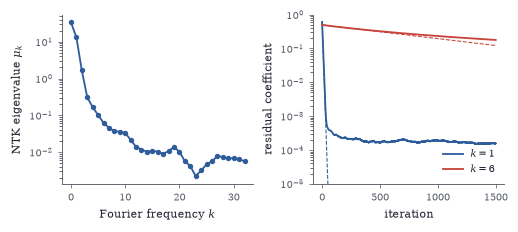

In [6]:
rng = np.random.default_rng(0); n, m = 64, 8000; tg = 2 * np.pi * np.arange(n) / n; Xc = np.c_[np.cos(tg), np.sin(tg), np.ones(n)] / np.sqrt(2)
Wn = rng.normal(size=(m, 3)); an = rng.choice([-1.0, 1.0], m)
def fnet(Wn, an): return np.maximum(Xc @ Wn.T, 0) @ an / np.sqrt(m)
def jnet(Wn, an):
    Zn = Xc @ Wn.T; return np.c_[np.maximum(Zn, 0) / np.sqrt(m), (((Zn > 0) * an)[:, :, None] * Xc[:, None, :] / np.sqrt(m)).reshape(n, -1)]
Th = jnet(Wn, an) @ jnet(Wn, an).T; muk = np.fft.fft(Th[0]).real; yt = np.sin(tg) + np.sin(6 * tg); eta = 0.015
r0 = np.abs(np.fft.fft(fnet(Wn, an) - yt) / n); W2, a2 = Wn.copy(), an.copy(); c1, c6 = [], []
for it in range(1500):
    rr = fnet(W2, a2) - yt; rh = np.abs(np.fft.fft(rr) / n); c1.append(rh[1]); c6.append(rh[6]); g = jnet(W2, a2).T @ rr; a2 -= eta * g[:m]; W2 -= eta * g[m:].reshape(m, 3)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0)); kk = np.arange(0, n // 2 + 1)
axs[0].semilogy(kk, np.maximum(muk[: n // 2 + 1], 1e-6), "o-", color=BLUE, ms=2.5); axs[0].set_xlabel("Fourier frequency $k$"); axs[0].set_ylabel(r"NTK eigenvalue $\mu_k$")
it = np.arange(1500)
for k, c, cc in [(1, BLUE, c1), (6, RED, c6)]: axs[1].semilogy(it, cc, color=c, label=f"$k={k}$"); axs[1].semilogy(it, r0[k] * (1 - eta * muk[k]) ** it, "--", color=c, lw=0.7)
axs[1].set_ylim(1e-5, 1); axs[1].set_xlabel("iteration"); axs[1].set_ylabel("residual coefficient"); axs[1].legend(fontsize=6.5, frameon=False)

In [7]:
rng = np.random.default_rng(0); X = rng.normal(size=(5, 12)); y = rng.normal(size=5); Xp = np.linalg.pinv(X); eta = 1 / np.linalg.norm(X, 2) ** 2
for w0 in (np.zeros(12), rng.normal(size=12)):
    w = w0.copy()
    for _ in range(20000): w -= eta * X.T @ (X @ w - y)
    print("start norm %.2f:  distance to predicted limit %.1e" % (np.linalg.norm(w0), np.linalg.norm(w - (Xp @ y + (np.eye(12) - Xp @ X) @ w0))))
for lam in (1e-1, 1e-3, 1e-6): print(f"lambda={lam:g}: ||w_ridge - X^+ y|| = {np.linalg.norm(np.linalg.solve(X.T @ X + lam * np.eye(12), X.T @ y) - Xp @ y):.2e}")

start norm 0.00:  distance to predicted limit 1.1e-15
start norm 4.12:  distance to predicted limit 2.8e-15
lambda=0.1: ||w_ridge - X^+ y|| = 6.15e-02
lambda=0.001: ||w_ridge - X^+ y|| = 6.54e-04
lambda=1e-06: ||w_ridge - X^+ y|| = 6.54e-07


In [8]:
from scipy.optimize import minimize
rng = np.random.default_rng(1); A = rng.uniform(size=(3, 8)); wt = rng.uniform(0.1, 1, 8); b = A @ wt; w0 = np.full(8, 0.5); w = w0.copy()
for _ in range(200000): w = w * np.exp(-0.05 * A.T @ (A @ w - b))
kl = minimize(lambda v: np.sum(v * np.log(v / w0) - v + w0), w0, constraints=[{"type": "eq", "fun": lambda v: A @ v - b}], bounds=[(1e-9, None)] * 8, method="SLSQP").x
print("exponentiated gradient:", np.round(w, 4)); print("Bregman (KL) projection:", np.round(kl, 4)); print("minimum Euclidean norm: ", np.round(np.linalg.pinv(A) @ b, 4))

exponentiated gradient: [0.7631 0.512  0.6586 0.8131 0.295  0.7071 0.5137 0.2544]
Bregman (KL) projection: [0.763  0.5121 0.6584 0.8131 0.295  0.7075 0.5135 0.2544]
minimum Euclidean norm:  [0.6725 0.4422 0.6041 0.873  0.2206 0.7661 0.5627 0.3065]


In [9]:
rng = np.random.default_rng(2); Wm = rng.normal(size=(6, 4)); P, s, Qt = np.linalg.svd(Wm, full_matrices=False)
bal = 0.5 * (np.sum(P**2 * s) + np.sum(Qt.T**2 * s)); unb = 0.5 * (np.sum((P * s) ** 2) + np.sum(Qt**2))
print(f"nuclear norm {s.sum():.4f}   balanced {bal:.4f}   unbalanced {unb:.4f}")
M = rng.normal(size=(6, 4)); U = rng.normal(size=(6, 4)) * 0.3; V = rng.normal(size=(4, 4)) * 0.3; C0 = U.T @ U - V.T @ V
for eta in (1e-2, 1e-3):
    Uu, Vv = U.copy(), V.copy()
    for _ in range(int(1 / eta)): R = Uu @ Vv.T - M; Uu, Vv = Uu - eta * R @ Vv, Vv - eta * R.T @ Uu
    print(f"eta={eta}: drift of U^T U - V^T V over unit time = {np.linalg.norm(Uu.T @ Uu - Vv.T @ Vv - C0):.2e}")

nuclear norm 7.1020   balanced 7.1020   unbalanced 10.2915
eta=0.01: drift of U^T U - V^T V over unit time = 3.24e-02
eta=0.001: drift of U^T U - V^T V over unit time = 3.24e-03


In [10]:
for L in (1, 2, 3):
    a, dt, t, hit = 1e-3, 1e-3, 0.0, None
    while t < 2000 and hit is None:
        a += dt * L * a ** (2 - 2 / L) * (1 - a); t += dt
        if a > 0.5: hit = t
    print(f"L={L}: time to reach a=0.5 is {hit:.2f}")

L=1: time to reach a=0.5 is 0.69
L=2: time to reach a=0.5 is 3.46
L=3: time to reach a=0.5 is 9.15


In [11]:
rng = np.random.default_rng(3); xtr = np.sort(rng.uniform(size=20)); ytr = np.sin(2 * np.pi * xtr) + 0.2 * rng.normal(size=20); xte = np.linspace(0, 1, 400)
kern = lambda a, b: np.exp(-(a[:, None] - b[None, :]) ** 2 / (2 * 0.1**2)); Ktr = kern(xtr, xtr)
print("condition number of K: %.1e" % np.linalg.cond(Ktr))
for lam in (0.0, 0.1):
    al = np.linalg.solve(Ktr + lam * np.eye(20), ytr); pred = kern(xte, xtr) @ al
    print(f"lambda={lam}: training error {np.sqrt(np.mean((Ktr @ al - ytr) ** 2)):.3f}   test error vs sin {np.sqrt(np.mean((pred - np.sin(2 * np.pi * xte)) ** 2)):.3f}")

condition number of K: 6.3e+11
lambda=0.0: training error 0.000   test error vs sin 974.084
lambda=0.1: training error 0.165   test error vs sin 0.158


In [12]:
rng = np.random.default_rng(4); Wr = rng.normal(size=(400000, 2))
for th in (0, np.pi / 3, np.pi / 2, np.pi):
    x, xp = np.array([1.0, 0]), np.array([np.cos(th), np.sin(th)]); z, zp = Wr @ x, Wr @ xp
    mc = np.mean(np.maximum(z, 0) * np.maximum(zp, 0)) + (x @ xp) * np.mean((z > 0) & (zp > 0))
    formula = (np.sin(th) + (np.pi - th) * np.cos(th)) / (2 * np.pi) + np.cos(th) * (np.pi - th) / (2 * np.pi)
    print(f"angle {th:.3f}: Monte Carlo {mc:.4f}   formula {formula:.4f}")

angle 0.000: Monte Carlo 0.9968   formula 1.0000
angle 1.047: Monte Carlo 0.4694   formula 0.4712
angle 1.571: Monte Carlo 0.1589   formula 0.1592
angle 3.142: Monte Carlo 0.0000   formula 0.0000


In [13]:
from scipy.special import iv
n, ell = 128, 0.5; th = 2 * np.pi * np.arange(n) / n; mu = np.fft.fft(np.exp(-(1 - np.cos(th)) / ell**2)).real
for k in (0, 1, 2, 4, 8): print(f"k={k}: eigenvalue {mu[k]:.4e}   Bessel formula {n * np.exp(-1 / ell**2) * iv(k, 1 / ell**2):.4e}")

k=0: eigenvalue 2.6496e+01   Bessel formula 2.6496e+01
k=1: eigenvalue 2.2880e+01   Bessel formula 2.2880e+01
k=2: eigenvalue 1.5056e+01   Bessel formula 1.5056e+01
k=4: eigenvalue 3.3203e+00   Bessel formula 3.3203e+00
k=8: eigenvalue 2.2998e-02   Bessel formula 2.2998e-02


In [14]:
rng = np.random.default_rng(5); P = rng.normal(size=(60, 3)); G = P @ P.T; D2 = np.sum(P**2, 1)[:, None] + np.sum(P**2, 1)[None, :] - 2 * G
Kg = np.exp(-D2 / 2); Kp = (1 + G) ** 3
for name, K in [("Gaussian", Kg), ("polynomial", Kp), ("sum", Kg + Kp), ("product", Kg * Kp), ("tanh(x.x' - 1)", np.tanh(G - 1))]:
    print(f"{name:15s} smallest eigenvalue {np.linalg.eigvalsh(K).min():+.2e}")

Gaussian        smallest eigenvalue +2.38e-05
polynomial      smallest eigenvalue -2.99e-13
sum             smallest eigenvalue +2.68e-05
product         smallest eigenvalue +3.38e-03
tanh(x.x' - 1)  smallest eigenvalue -2.92e+01
